# NIH Chest X-ray Data Preparation

Run the cells from top to bottom. This notebook:
1. Loads the image archive.
2. Checks and prepares images.
3. Summarizes the data with NumPy and pandas.
4. Creates patient-level train, validation, and test splits.

Splits are provisional because official split lists are not present. No labels are invented.

In [1]:
# 1. Imports and paths
import os, re, io, tarfile, hashlib, json
from collections import Counter
import numpy as np
import pandas as pd
from PIL import Image, ImageFile, ImageOps

ImageFile.LOAD_TRUNCATED_IMAGES = False
ARCHIVE = 'nih_chestxray14/images/images_004.tar.gz'
ROOT = 'nih_chestxray14'
CLEAN_DIR = os.path.join(ROOT, 'cleaned')
CLEAN_IMAGES = os.path.join(CLEAN_DIR, 'images')
EDA_DIR = os.path.join(ROOT, 'eda')
TARGET_SIZE = (224, 224)  # baseline_model.keras input is (None, 224, 224, 3)
os.makedirs(CLEAN_IMAGES, exist_ok=True)
os.makedirs(EDA_DIR, exist_ok=True)
assert os.path.exists(ARCHIVE), f'Archive not found: {ARCHIVE}'
print('Archive size (GB):', round(os.path.getsize(ARCHIVE)/1e9, 2))

Archive size (GB): 3.84


## 1. Check the archive

In [2]:
with tarfile.open(ARCHIVE, 'r:gz') as tar:
    png_members = [m for m in tar if m.isfile() and m.name.lower().endswith('.png')]
print('PNG count:', len(png_members))
print('First filenames:', [os.path.basename(m.name) for m in png_members[:10]])

PNG count: 10000
First filenames: ['00008468_031.png', '00007408_001.png', '00007747_001.png', '00007245_002.png', '00008151_001.png', '00008067_009.png', '00008411_005.png', '00008922_008.png', '00007157_001.png', '00006774_007.png']


## 2. Clean and prepare images

The original archive remains unchanged. Each image is fully decoded, hashed for exact duplicate detection, oriented using EXIF metadata if present, converted to RGB, and resized to 224×224 using Lanczos. Pixel values remain in the 0–255 range; model-specific scaling is not applied because the expected normalization is not documented by the input shape.

In [3]:
records, rejected = [], []
seen_hashes = {}
source_modes, source_dimensions = Counter(), Counter()

with tarfile.open(ARCHIVE, 'r:gz') as tar:
    members = [m for m in tar if m.isfile() and m.name.lower().endswith('.png')]
    for i, member in enumerate(members, 1):
        name = os.path.basename(member.name)
        match = re.match(r'^(\d+)_', name)
        patient_id = match.group(1) if match else ''
        try:
            stream = tar.extractfile(member)
            if stream is None:
                raise ValueError('Could not read archive member')
            raw = stream.read()
            digest = hashlib.sha256(raw).hexdigest()
            with Image.open(io.BytesIO(raw)) as image:
                image.load()  # detects corrupt or truncated PNGs
                width, height = image.size
                mode = image.mode
                gray = np.asarray(image.convert('L'), dtype=np.uint8)
                prepared = ImageOps.exif_transpose(image).convert('RGB')
                prepared = prepared.resize(TARGET_SIZE, Image.Resampling.LANCZOS)
            source_modes[mode] += 1
            source_dimensions[f'{width}x{height}'] += 1
            duplicate_of = seen_hashes.get(digest, '')
            if not duplicate_of:
                seen_hashes[digest] = name
            output_path = os.path.join(CLEAN_IMAGES, name)
            prepared.save(output_path, format='PNG', optimize=True)
            records.append({
                'image': name, 'patient_id_from_filename': patient_id,
                'source_member': member.name, 'source_sha256': digest,
                'duplicate_of': duplicate_of, 'source_width': width,
                'source_height': height, 'source_mode': mode,
                'source_bytes': len(raw), 'mean_intensity': float(gray.mean()),
                'std_intensity': float(gray.std()), 'min_intensity': int(gray.min()),
                'max_intensity': int(gray.max()), 'prepared_width': TARGET_SIZE[0],
                'prepared_height': TARGET_SIZE[1], 'prepared_mode': 'RGB',
                'prepared_path': os.path.relpath(output_path, ROOT), 'status': 'prepared'
            })
        except Exception as exc:
            rejected.append({'image': name, 'source_member': member.name, 'reason': repr(exc)})
        if i % 1000 == 0:
            print(f'Processed {i}/{len(members)}')

clean_df = pd.DataFrame(records)
rejected_df = pd.DataFrame(rejected, columns=['image', 'source_member', 'reason'])
print('Prepared:', len(clean_df), '| rejected:', len(rejected_df))
clean_df.head()

Processed 1000/10000
Processed 2000/10000
Processed 3000/10000
Processed 4000/10000
Processed 5000/10000
Processed 6000/10000
Processed 7000/10000
Processed 8000/10000
Processed 9000/10000
Processed 10000/10000
Prepared: 10000 | rejected: 0


,image,patient_id_from_filename,source_member,source_sha256,duplicate_of,source_width,source_height,source_mode,source_bytes,mean_intensity,std_intensity,min_intensity,max_intensity,prepared_width,prepared_height,prepared_mode,prepared_path,status
0,00008468_031.png,00008468,images/00008468_031.png,4c3c7ce9201a1b7b2aca9287a786cc497e90eed0be5794...,,1024,1024,L,474636,107.811021,54.625442,0,255,224,224,RGB,cleaned/images/00008468_031.png,prepared
1,00007408_001.png,00007408,images/00007408_001.png,86641b786d09e2b8179b758ee28c6491257df4b3837e18...,,1024,1024,L,361333,155.020240,63.643269,0,250,224,224,RGB,cleaned/images/00007408_001.png,prepared
2,00007747_001.png,00007747,images/00007747_001.png,b649e70341be072188e367579f06332cea6a342a23f1a9...,,1024,1024,L,360981,156.673311,51.843194,2,247,224,224,RGB,cleaned/images/00007747_001.png,prepared
3,00007245_002.png,00007245,images/00007245_002.png,d6ff4050ffb472e14fafb0f855327c7e32699194b501ad...,,1024,1024,L,351224,156.924585,39.736453,2,226,224,224,RGB,cleaned/images/00007245_002.png,prepared
4,00008151_001.png,00008151,images/00008151_001.png,6242808507a6629d088fc6ac24dd9732d8e72a8c498c43...,,1024,1024,L,395999,177.648625,52.037911,5,255,224,224,RGB,cleaned/images/00008151_001.png,prepared


## 3. Save cleaned data

In [4]:
clean_manifest = os.path.join(CLEAN_DIR, 'cleaned_manifest.csv')
rejected_manifest = os.path.join(CLEAN_DIR, 'rejected_manifest.csv')
clean_df.to_csv(clean_manifest, index=False)
rejected_df.to_csv(rejected_manifest, index=False)
print('Saved:', clean_manifest)
print('Saved:', rejected_manifest)

Saved: nih_chestxray14/cleaned/cleaned_manifest.csv
Saved: nih_chestxray14/cleaned/rejected_manifest.csv


## 4. Check data quality

In [5]:
print('Rows:', len(clean_df))
print('Duplicate source hashes:', int(clean_df['source_sha256'].duplicated().sum()))
print('Missing values by column:')
display(clean_df.isna().sum().to_frame('missing_count'))
print('Original image dimensions:')
display(clean_df.groupby(['source_width', 'source_height']).size().rename('count').to_frame())
print('Original color modes:')
display(clean_df['source_mode'].value_counts().to_frame('count'))
print('Prepared shape/mode check:')
display(clean_df.groupby(['prepared_width', 'prepared_height', 'prepared_mode']).size().rename('count').to_frame())

Rows: 10000
Duplicate source hashes: 0
Missing values by column:


,missing_count
image,0
patient_id_from_filename,0
source_member,0
source_sha256,0
duplicate_of,0
source_width,0
source_height,0
source_mode,0
source_bytes,0
mean_intensity,0


Original image dimensions:


,,count
source_width,source_height,
1024,1024,10000


Original color modes:


,count
source_mode,
L,9931
RGBA,69


Prepared shape/mode check:


,,,count
prepared_width,prepared_height,prepared_mode,
224,224,RGB,10000


## 5. Explore with NumPy and pandas

In [6]:
numeric_cols = ['source_bytes', 'mean_intensity', 'std_intensity']
numeric_summary = clean_df[numeric_cols].describe().T
display(numeric_summary)
numeric_summary.to_csv(os.path.join(EDA_DIR, 'numeric_summary.csv'))

patient_counts = clean_df.groupby('patient_id_from_filename').size().rename('image_count')
patient_summary = patient_counts.describe().to_frame()
display(patient_summary)
patient_summary.to_csv(os.path.join(EDA_DIR, 'images_per_patient_summary.csv'))
print('Unique filename-derived patient IDs:', patient_counts.size)
clean_df[['image', 'patient_id_from_filename']].to_csv(
    os.path.join(EDA_DIR, 'filename_patient_groups.csv'), index=False)
clean_df.groupby(['source_width', 'source_height', 'source_mode']).size().rename(
    'image_count').reset_index().to_csv(os.path.join(EDA_DIR, 'image_format_counts.csv'), index=False)

,count,mean,std,min,25%,50%,75%,max
source_bytes,10000.0,383726.739800,41404.817202,135295.000000,359225.750000,382067.500000,400927.000000,789842.000000
mean_intensity,10000.0,145.225359,22.715938,37.068234,128.401233,152.344091,162.038040,219.511774
std_intensity,10000.0,56.336071,10.263843,5.116926,48.843964,56.183301,64.055199,95.077578


,image_count
count,2648.000000
mean,3.776435
std,6.568394
min,1.000000
25%,1.000000
50%,1.000000
75%,4.000000
max,83.000000


Unique filename-derived patient IDs: 2648


## 6. Plot the data

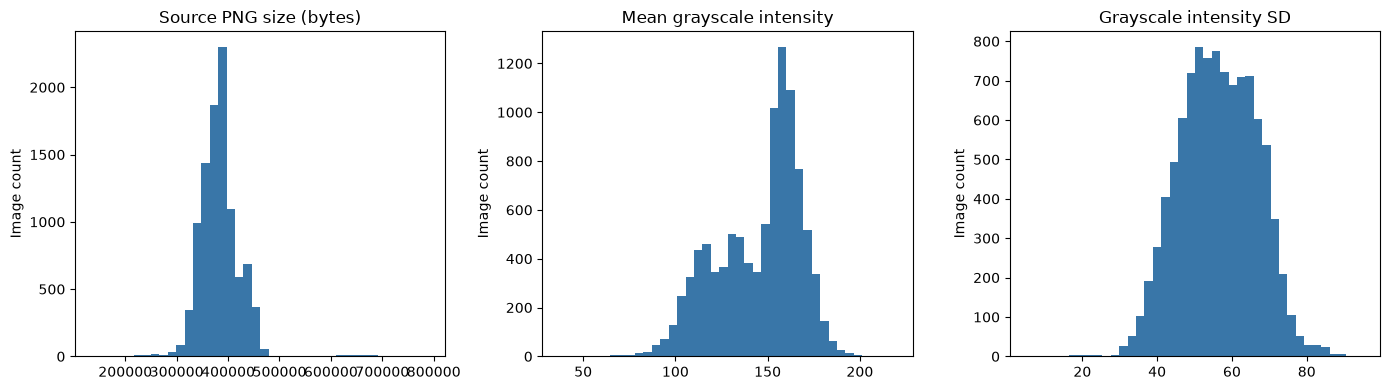

Saved: nih_chestxray14/eda/cleaning_eda_overview.png


In [7]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col, title in zip(axes, numeric_cols,
                          ['Source PNG size (bytes)', 'Mean grayscale intensity', 'Grayscale intensity SD']):
    ax.hist(clean_df[col].to_numpy(), bins=40, color='#3976a8')
    ax.set_title(title)
    ax.set_ylabel('Image count')
fig.tight_layout()
plot_path = os.path.join(EDA_DIR, 'cleaning_eda_overview.png')
fig.savefig(plot_path, dpi=160)
plt.show()
print('Saved:', plot_path)

## 7. View sample images

00008468_031.png


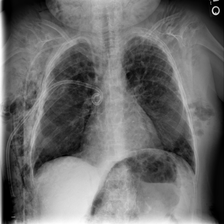

00007408_001.png


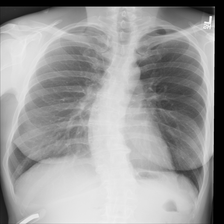

00007747_001.png


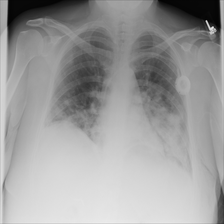

00007245_002.png


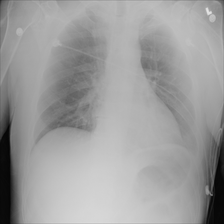

00008151_001.png


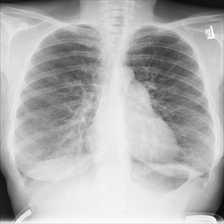

00008067_009.png


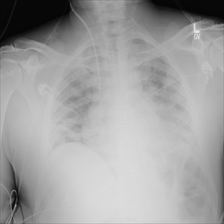

00008411_005.png


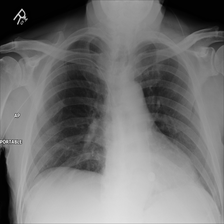

00008922_008.png


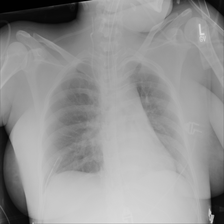

In [8]:
from IPython.display import display
from PIL import Image as PILImage
sample_paths = clean_df['prepared_path'].head(8).tolist()
for rel_path in sample_paths:
    path = os.path.join(ROOT, rel_path)
    print(os.path.basename(path))
    display(PILImage.open(path))

## 8. Create patient-level splits and save report

In [9]:
# Reproducible patient-level 70/15/15 split
# All images from one patient stay in exactly one split.
SEED = 42
patient_ids = patient_counts.index.to_numpy().copy()
rng = np.random.default_rng(SEED)
rng.shuffle(patient_ids)
n = len(patient_ids)
n_train = int(n * 0.70)
n_val = int(n * 0.15)
train_ids = set(patient_ids[:n_train])
val_ids = set(patient_ids[n_train:n_train + n_val])
test_ids = set(patient_ids[n_train + n_val:])

def choose_split(patient_id):
    if patient_id in train_ids: return 'train'
    if patient_id in val_ids: return 'validation'
    return 'test'

clean_df['split'] = clean_df['patient_id_from_filename'].map(choose_split)
split_file = os.path.join(CLEAN_DIR, 'split_manifest.csv')
clean_df[['image', 'patient_id_from_filename', 'split']].to_csv(split_file, index=False)
split_summary = clean_df.groupby('split').agg(
    images=('image', 'count'), patients=('patient_id_from_filename', 'nunique'))
display(split_summary)

# Leakage check: patient ID sets must not overlap.
assert train_ids.isdisjoint(val_ids)
assert train_ids.isdisjoint(test_ids)
assert val_ids.isdisjoint(test_ids)
print('Patient overlap check passed.')

report = {
    'archive': ARCHIVE, 'images_listed': len(members),
    'prepared_images': len(clean_df), 'rejected_images': len(rejected_df),
    'exact_duplicate_source_images': int(clean_df['source_sha256'].duplicated().sum()),
    'unique_filename_patient_ids': int(clean_df['patient_id_from_filename'].nunique()),
    'split_method': 'random patient-level split; seed=42; target 70/15/15',
    'split_counts': split_summary.reset_index().to_dict(orient='records'),
    'split_manifest': split_file,
    'preparation': 'EXIF orientation, RGB conversion, Lanczos resize to 224x224; pixels remain 0-255',
    'labels': 'Not present in the available files; none inferred',
    'split_warning': 'Provisional split, not the official NIH split list.'
}
report_path = os.path.join(CLEAN_DIR, 'cleaning_report.json')
with open(report_path, 'w') as f:
    json.dump(report, f, indent=2)
print(json.dumps(report, indent=2))
print('Saved:', report_path)

,images,patients
split,,
test,1363,398
train,7292,1853
validation,1345,397


Patient overlap check passed.
{
  "archive": "nih_chestxray14/images/images_004.tar.gz",
  "images_listed": 10000,
  "prepared_images": 10000,
  "rejected_images": 0,
  "exact_duplicate_source_images": 0,
  "unique_filename_patient_ids": 2648,
  "split_method": "random patient-level split; seed=42; target 70/15/15",
  "split_counts": [
    {
      "split": "test",
      "images": 1363,
      "patients": 398
    },
    {
      "split": "train",
      "images": 7292,
      "patients": 1853
    },
    {
      "split": "validation",
      "images": 1345,
      "patients": 397
    }
  ],
  "split_manifest": "nih_chestxray14/cleaned/split_manifest.csv",
  "preparation": "EXIF orientation, RGB conversion, Lanczos resize to 224x224; pixels remain 0-255",
  "labels": "Not present in the available files; none inferred",
  "split_warning": "Provisional split, not the official NIH split list."
}
Saved: nih_chestxray14/cleaned/cleaning_report.json
